<a href="https://colab.research.google.com/github/Adji30/IBM-Data-Analysis/blob/main/Web_Scraping_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDA0321ENSkillsNetwork928-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Hands-on Lab : Web Scraping**


Estimated time needed: **30 to 45** minutes


## Objectives


In this lab you will perform the following:


* Extract information from a given web site
* Write the scraped data into a csv file.


## Extract information from the given web site
You will extract the data from the below web site: <br>


In [1]:
#this url contains the data you need to scrape
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DA0321EN-SkillsNetwork/labs/datasets/Programming_Languages.html"

The data you need to scrape is the **name of the programming language** and **average annual salary**.<br> It is a good idea to open the url in your web broswer and study the contents of the web page before you start to scrape.


Import the required libraries


In [2]:
# Your code here
import pandas as pd
from bs4 import BeautifulSoup # this module helps in web scrapping.
import requests  # this module helps us to download a webpage

Download the webpage at the url


In [3]:
#your code goes here
data  = requests.get(url).text

Create a soup object


In [4]:
#your code goes here
soup = BeautifulSoup(data,"html.parser")
table = soup.find("table")

Scrape the `Language name` and `annual average salary`.


In [5]:
#your code goes here
language_list = []

for row in table.find_all("tr"):
  cols = row.find_all("td")
  if len(cols) > 0:
        language_name = cols[1].getText()
        annual_average_salary = cols[3].getText()
        language_list.append([language_name, annual_average_salary])


Save the scrapped data into a file named *popular-languages.csv*


In [6]:
# your code goes here
df = pd.DataFrame(language_list, columns=["Language Name", "Average Annual Salary"])
df.to_csv("popular-languages.csv", index=False)

In [7]:
df.head()

,Language Name,Average Annual Salary
0,Language,Average Annual Salary
1,Python,"$114,383"
2,Java,"$101,013"
3,R,"$92,037"
4,Javascript,"$110,981"


/tmp/ipykernel_469/3143631144.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Average Annual Salary', y="Language Name", data=df, palette='magma')


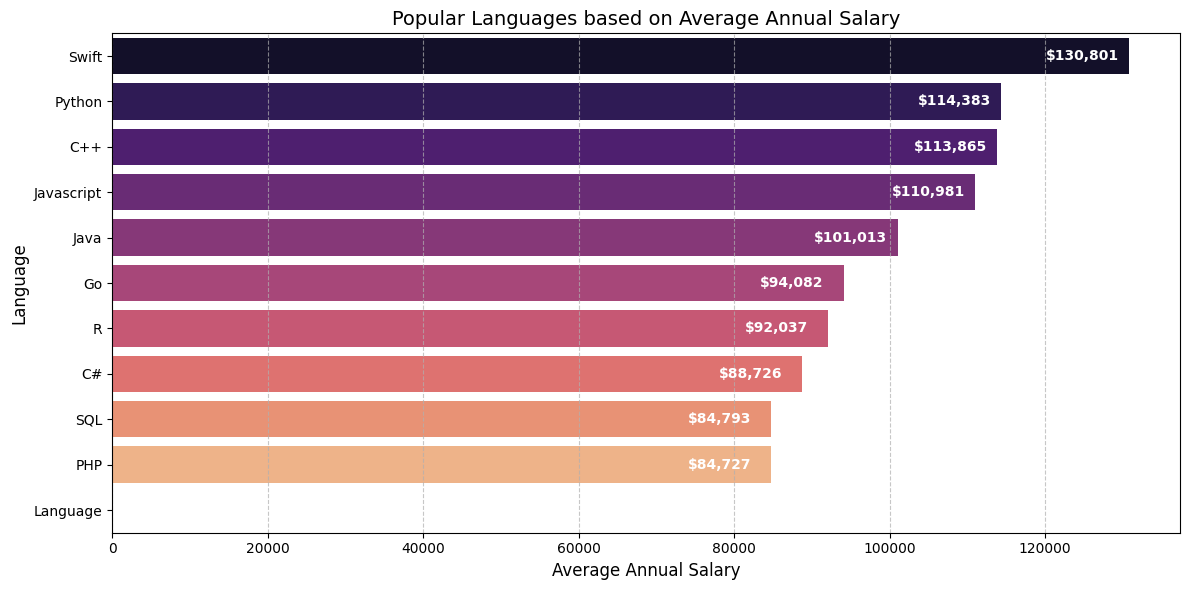

In [8]:
!pip install seaborn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df['Average Annual Salary'] = pd.to_numeric(
    df['Average Annual Salary']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce')

df = df.sort_values(by='Average Annual Salary', ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='Average Annual Salary', y="Language Name", data=df, palette='magma')
plt.title('Popular Languages based on Average Annual Salary', fontsize=14)
plt.xlabel("Average Annual Salary", fontsize=12)
plt.ylabel("Language", fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.7)

for p in ax.patches:
    width = p.get_width()
    # Menambahkan teks di ujung batang (format angka dengan pemisah koma dan simbol $)
    ax.annotate(f"${width:,.0f}",
                (width, p.get_y() + p.get_height() / 2.),
                xytext=(-60, 0),
                textcoords='offset points',
                ha='left', va='center',
                fontsize=10, fontweight='bold', color='white')

plt.tight_layout()
plt.show()

## Authors


Ramesh Sannareddy


### Other Contributors


Rav Ahuja


## Change Log


|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-10-17  | 0.1  | Ramesh Sannareddy  |  Created initial version of the lab |


 Copyright &copy; 2020 IBM Corporation. This notebook and its source code are released under the terms of the [MIT License](https://cognitiveclass.ai/mit-license/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDA0321ENSkillsNetwork928-2022-01-01).
